# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Prima Surya Nusantara | 5054251036 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [36]:
import kagglehub
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

In [37]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

file_csv = Path(path) / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_csv)

display(df.head())

df.info()

print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [38]:
print(f"Jumlah missing value: {df.isna().sum().sum()}")

Jumlah missing value: 0


In [39]:
kolom_numerik = ["tenure", "MonthlyCharges", "TotalCharges"]

kolom_id = ["customerID"]

kolom_target = ["Churn"]

kolom_kategorikal = [kolom for kolom in df.columns if kolom not in kolom_numerik + kolom_id + kolom_target]

print("Kolom numerik:", kolom_numerik)
print("Kolom kategorikal:", kolom_kategorikal)
print("Kolom ID:", kolom_id)

print(f"\nJumlah kolom numerik: {len(kolom_numerik)}")
print(f"Jumlah kolom kategorikal: {len(kolom_kategorikal)}")

Kolom numerik: ['tenure', 'MonthlyCharges', 'TotalCharges']
Kolom kategorikal: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Kolom ID: ['customerID']

Jumlah kolom numerik: 3
Jumlah kolom kategorikal: 16


In [40]:
numerik = df[kolom_numerik].apply(pd.to_numeric, errors="coerce")

statistik = numerik.describe().T

statistik = statistik.rename(columns={"50%": "median"})
statistik["modus"] = numerik.mode().iloc[0]
statistik["IQR"] = statistik["75%"] - statistik["25%"]
statistik["skewness"] = numerik.skew()

display(statistik)

print("Jumlah nilai kosong/tidak dapat dibaca sebagai angka:")
print(numerik.isna().sum())

,count,mean,std,min,25%,median,75%,max,modus,IQR,skewness
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,1.00,46.0000,0.239540
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,20.05,54.3500,-0.220524
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,20.20,3393.2875,0.961642


Jumlah nilai kosong/tidak dapat dibaca sebagai angka:
tenure             0
MonthlyCharges     0
TotalCharges      11
dtype: int64


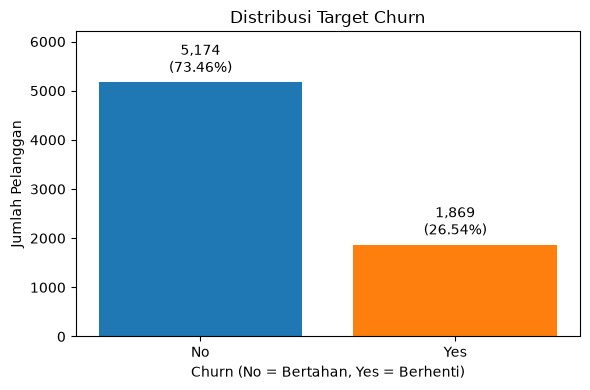

In [41]:
jumlah_distribusi_target = df["Churn"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))

batang = ax.bar(jumlah_distribusi_target.index, jumlah_distribusi_target.values, color=["#1f77b4", "#ff7f0e"])

label = [f"{nilai:,}\n({nilai / jumlah_distribusi_target.sum() * 100:.2f}%)" for nilai in jumlah_distribusi_target.values]

ax.bar_label(batang, labels=label, padding=4)

ax.set_title("Distribusi Target Churn")
ax.set_xlabel("Churn (No = Bertahan, Yes = Berhenti)")
ax.set_ylabel("Jumlah Pelanggan")
ax.set_ylim(0, jumlah_distribusi_target.max() * 1.2)

plt.tight_layout()
plt.show()


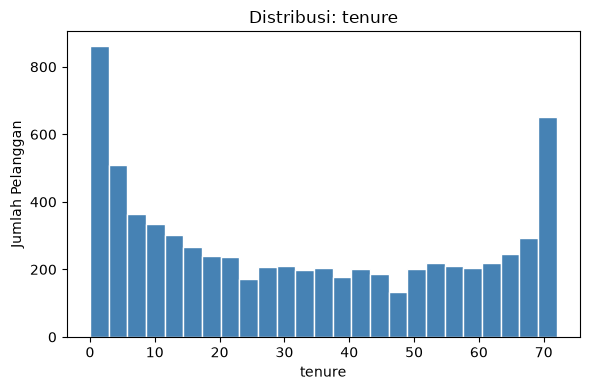

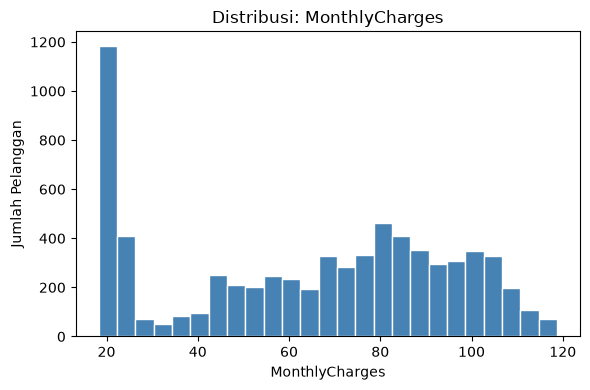

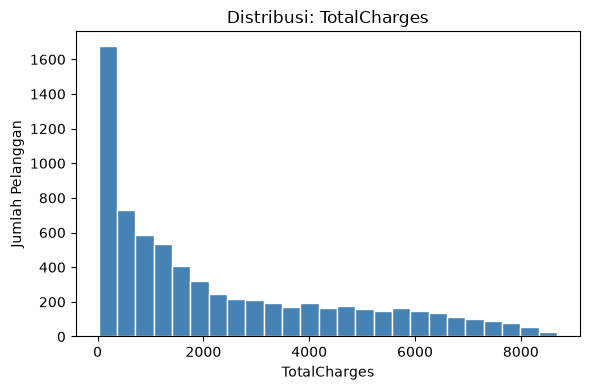

In [42]:
for kolom in kolom_numerik:
        fig, ax = plt.subplots(figsize=(6, 4))

        ax.hist(numerik[kolom].dropna(),
        bins=25,
        color="steelblue",
        edgecolor="white")

        ax.set_title(f"Distribusi: {kolom}")
        ax.set_xlabel(kolom)
        ax.set_ylabel("Jumlah Pelanggan")

        plt.tight_layout()
        plt.show()

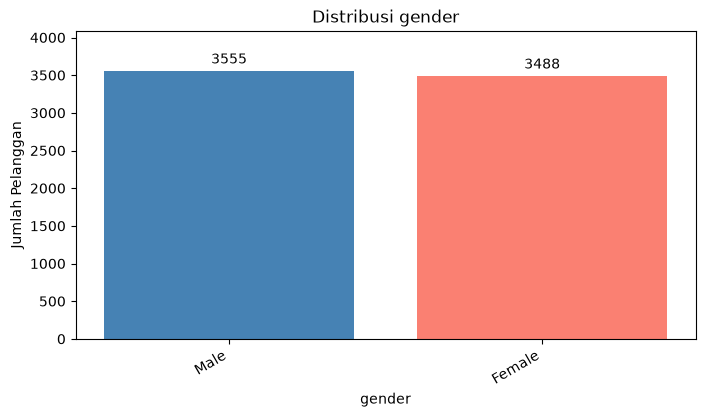

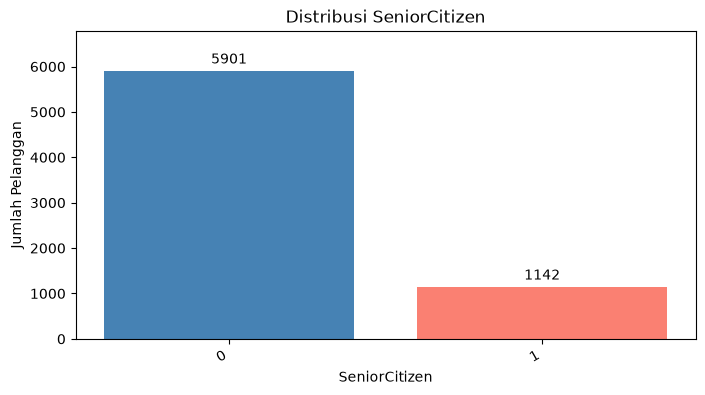

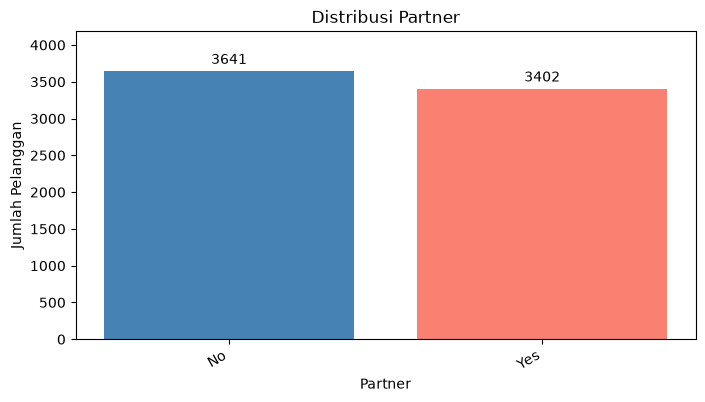

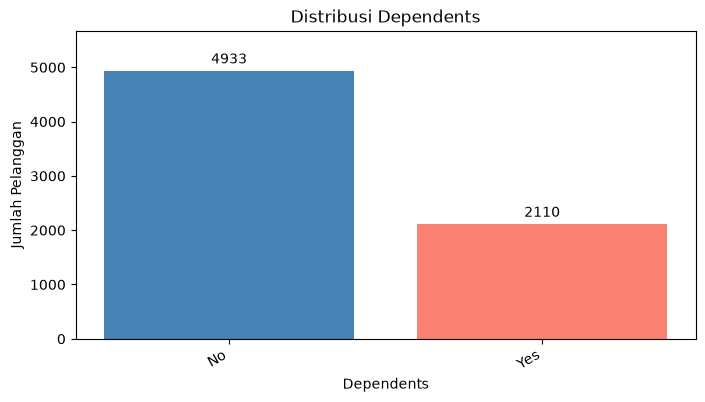

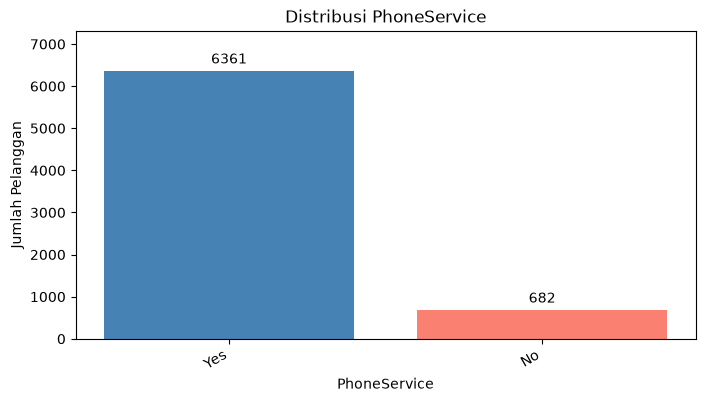

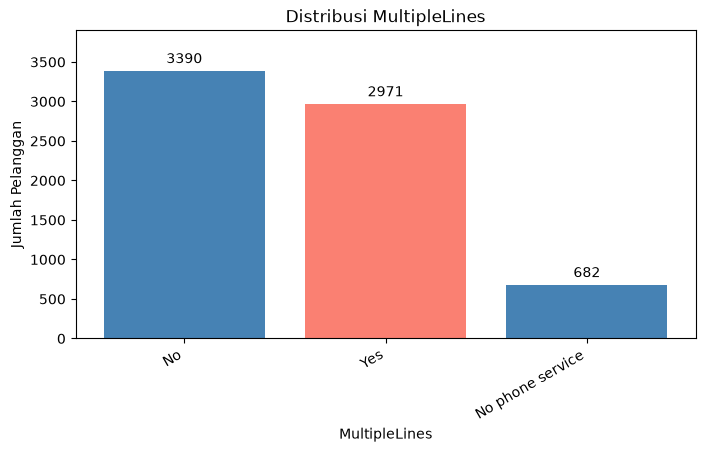

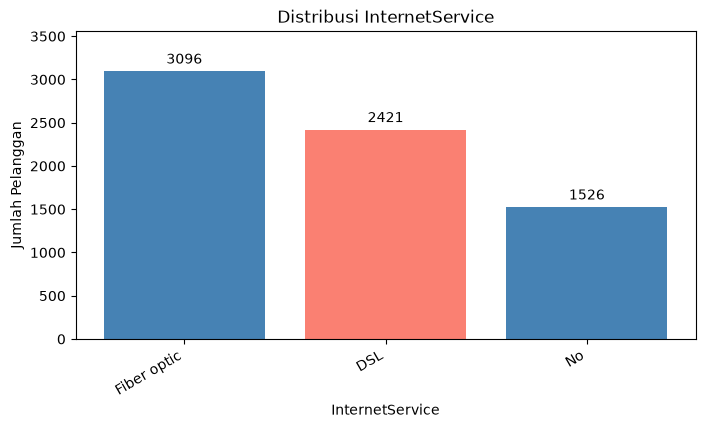

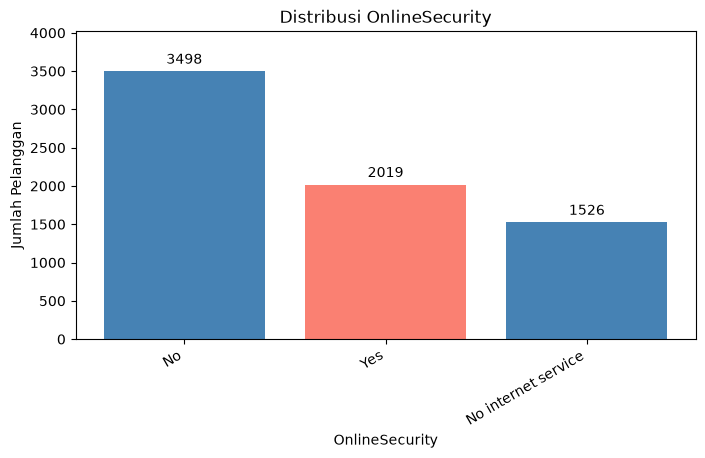

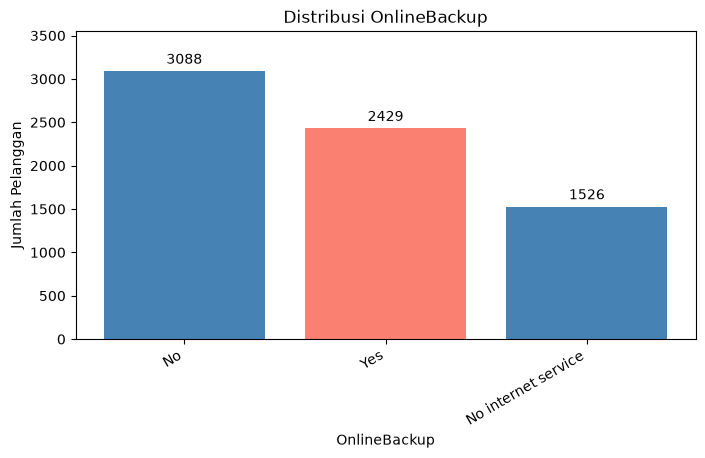

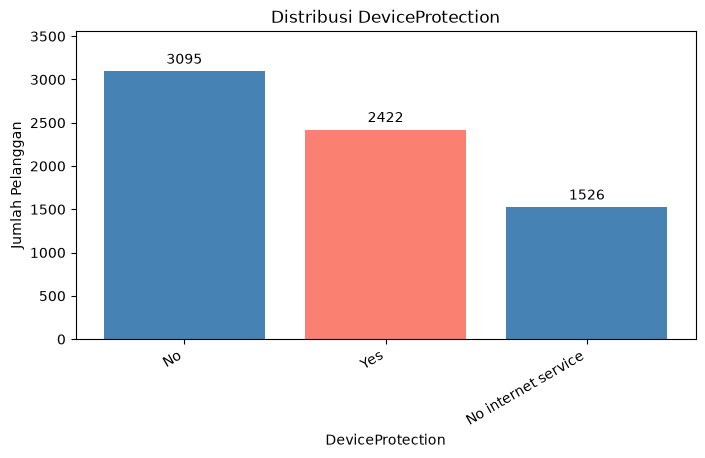

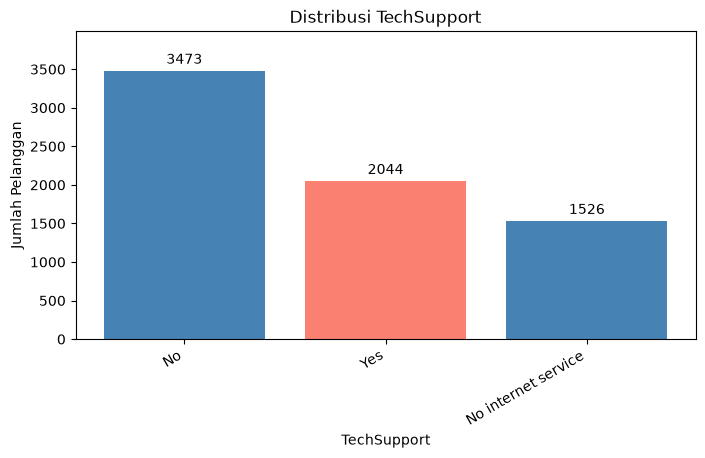

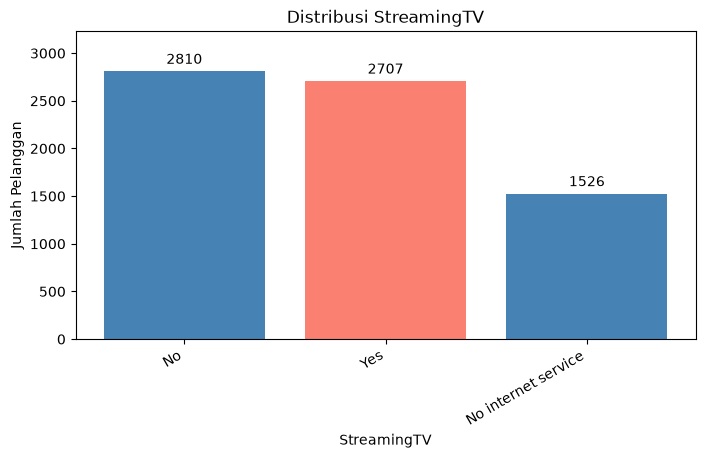

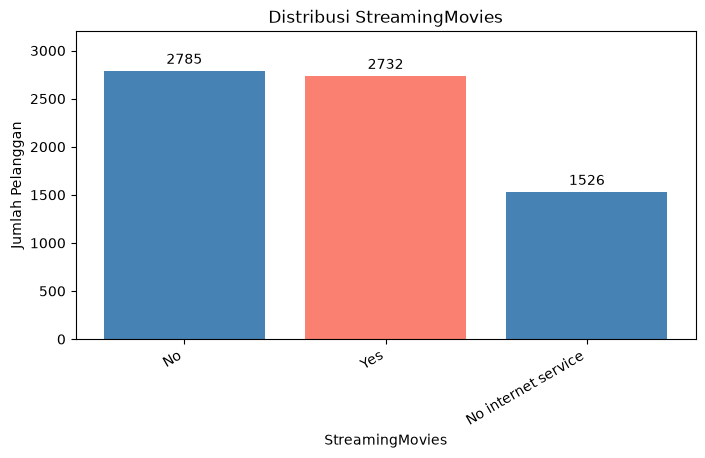

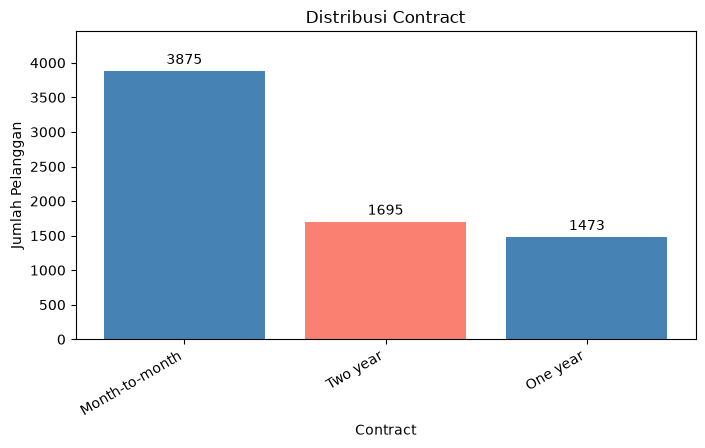

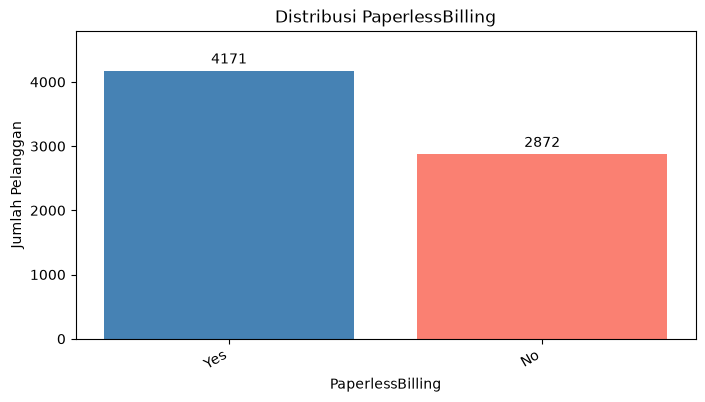

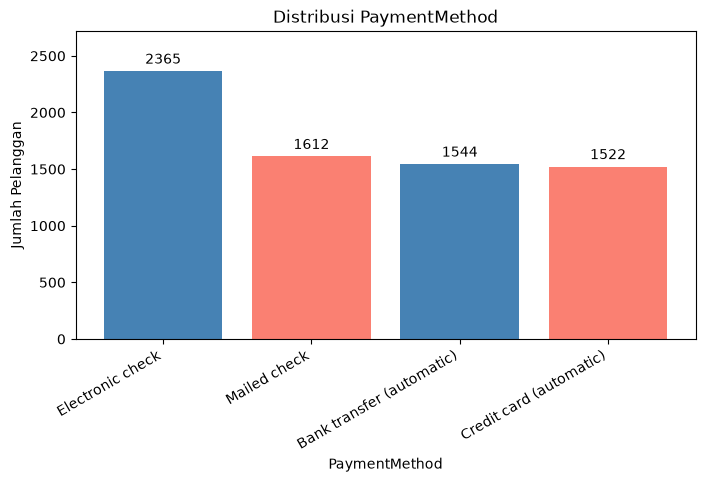

In [43]:
for kolom in kolom_kategorikal:
    jumlah = df[kolom].value_counts(dropna=False)

    fig, ax = plt.subplots(figsize=(8, 4))

    batang = ax.bar(
        jumlah.index.astype(str),
        jumlah.values,
        color=[color for color in ["steelblue", "salmon"]]
    )

    ax.bar_label(batang, padding=3)

    ax.set_title(f"Distribusi {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Jumlah Pelanggan")
    ax.set_ylim(0, jumlah.max() * 1.15)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

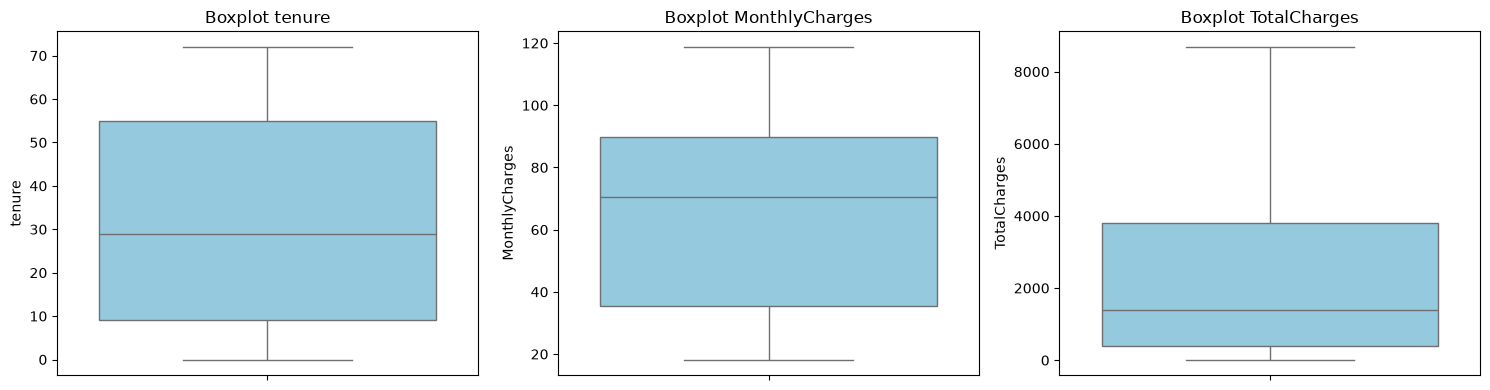

In [44]:
fig, axes = plt.subplots(
    1, len(kolom_numerik),
    figsize=(15, 4)
)

for ax, kolom in zip(axes, kolom_numerik):
    sns.boxplot(
        y=numerik[kolom],
        ax=ax,
        color="skyblue"
    )

    ax.set_title(f"Boxplot {kolom}")
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.show()

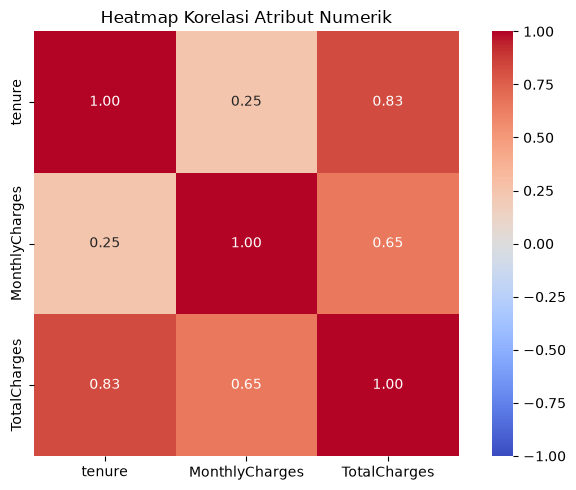

In [45]:
korelasi = numerik.corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Heatmap Korelasi Atribut Numerik")
plt.tight_layout()
plt.show()

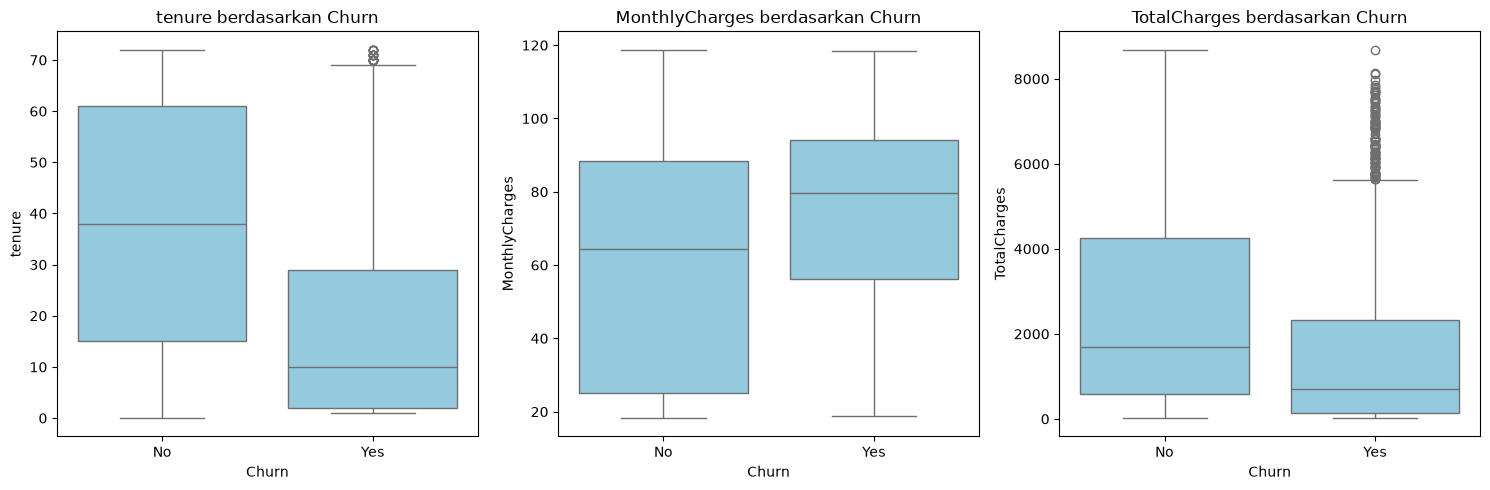

In [46]:
data_plot = numerik.join(df["Churn"])

fig, axes = plt.subplots(
    1, len(kolom_numerik),
    figsize=(15, 5)
)

for ax, kolom in zip(axes, kolom_numerik):
    sns.boxplot(
        data=data_plot,
        x="Churn",
        y=kolom,
        order=["No", "Yes"],
        color="skyblue",
        ax=ax
    )

    ax.set_title(f"{kolom} berdasarkan Churn")
    ax.set_xlabel("Churn")
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.show()

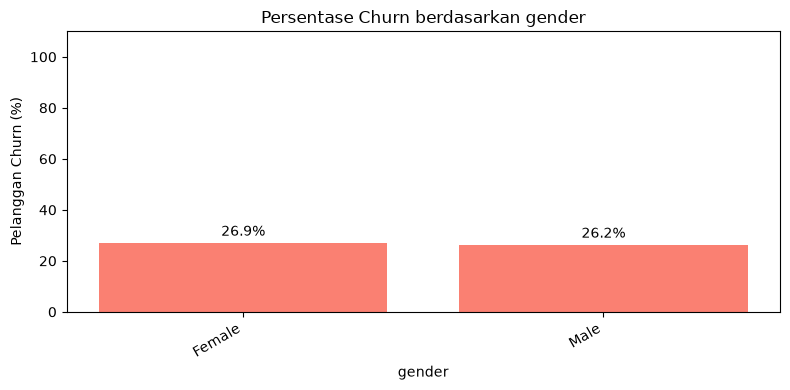

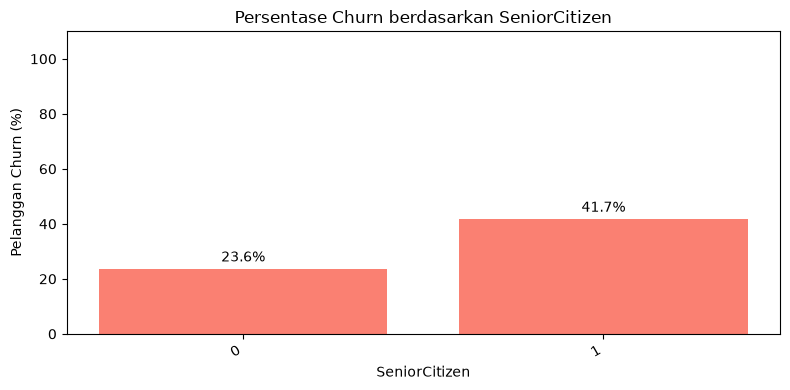

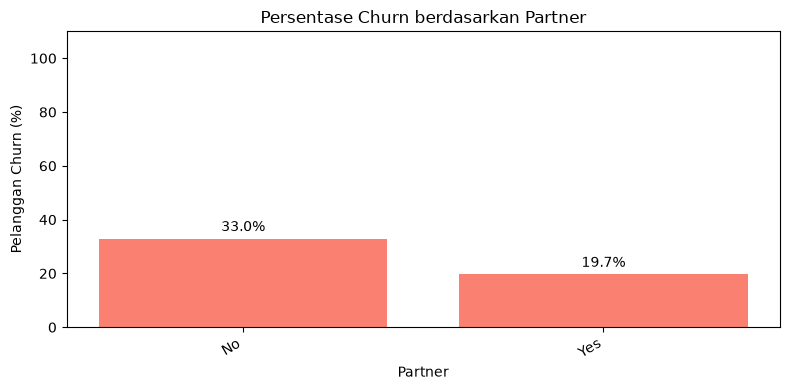

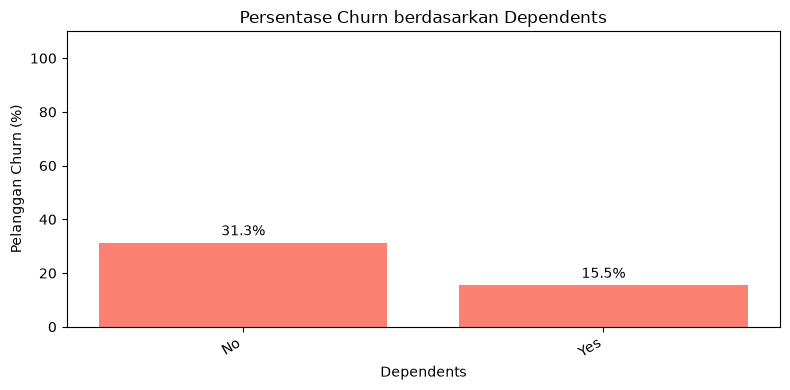

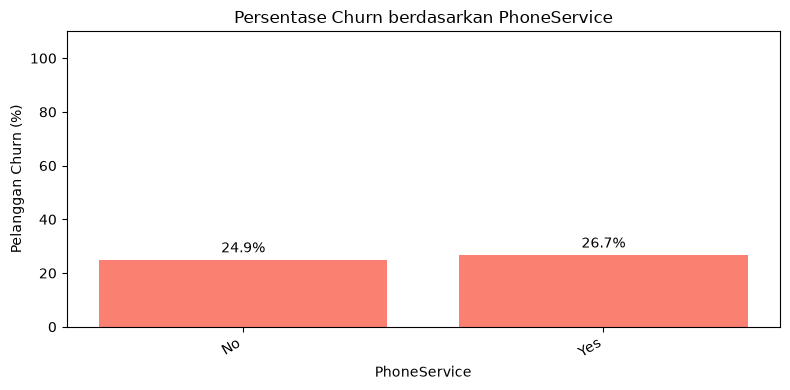

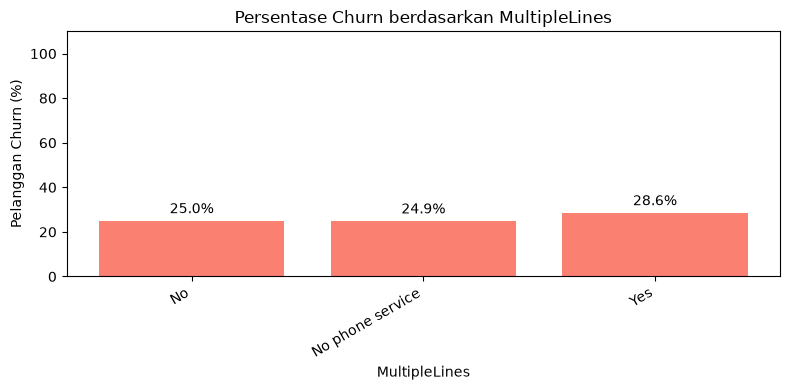

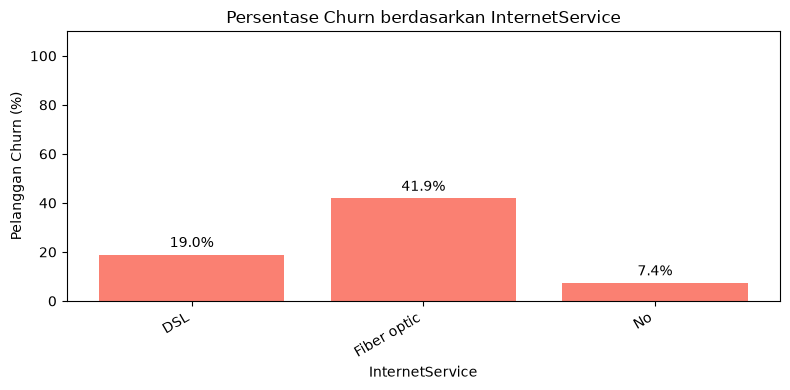

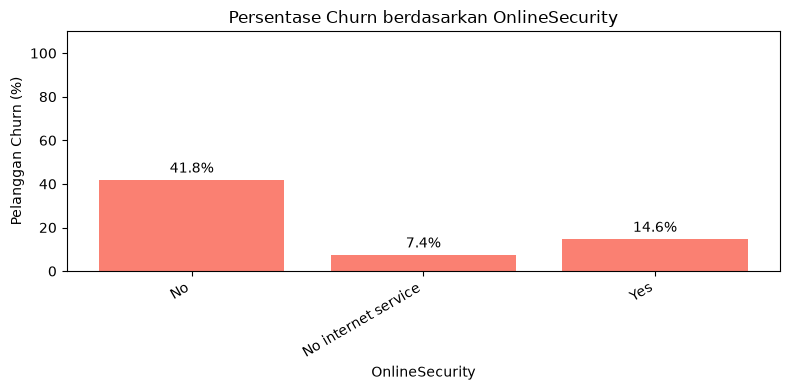

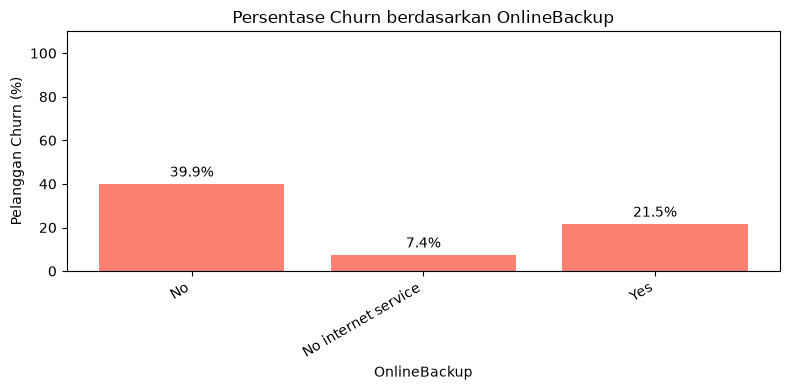

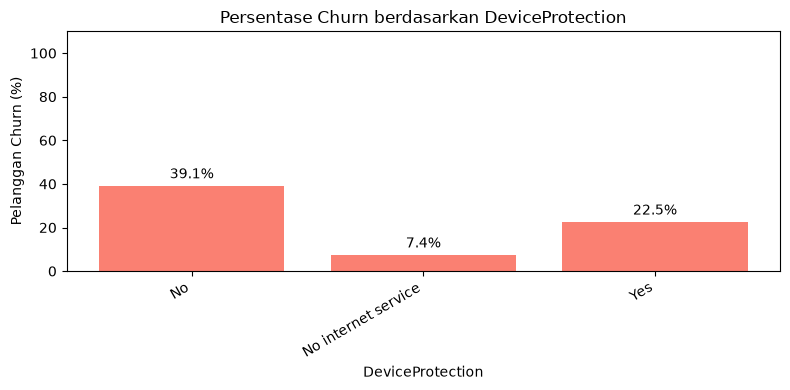

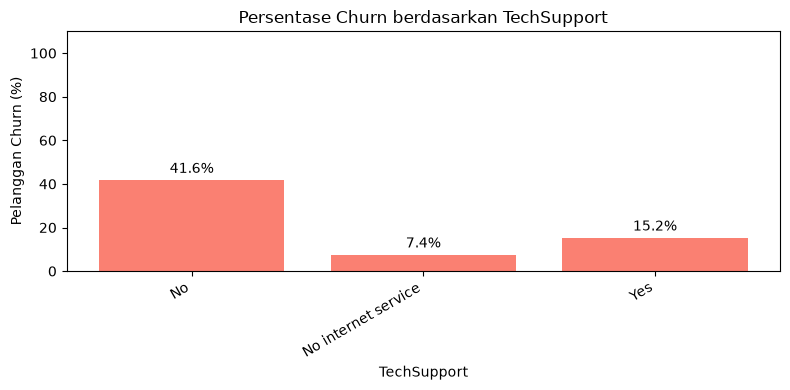

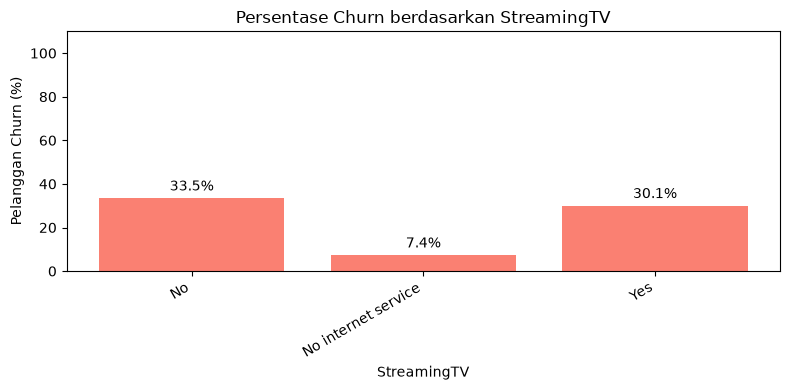

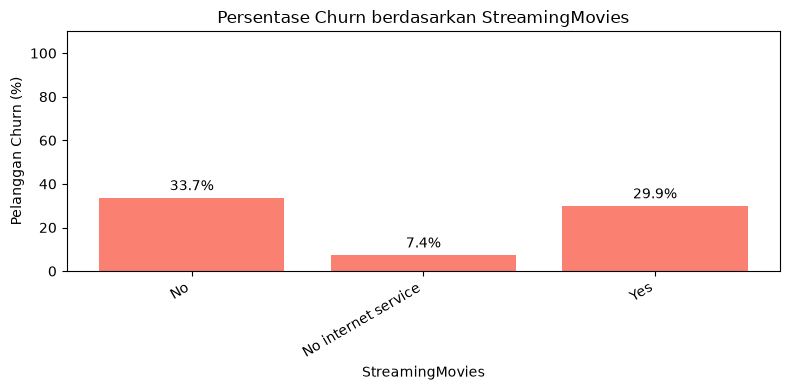

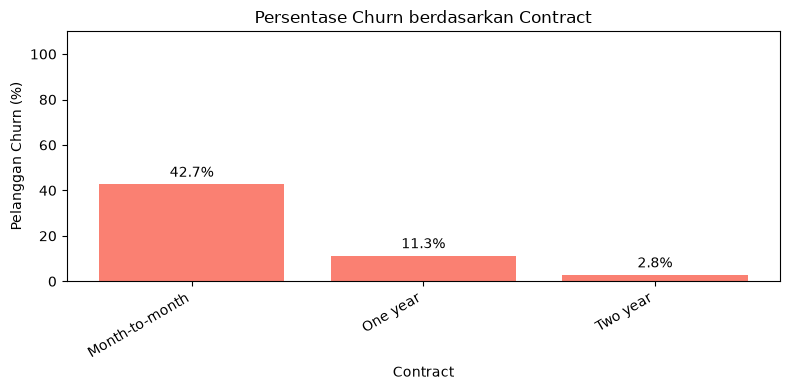

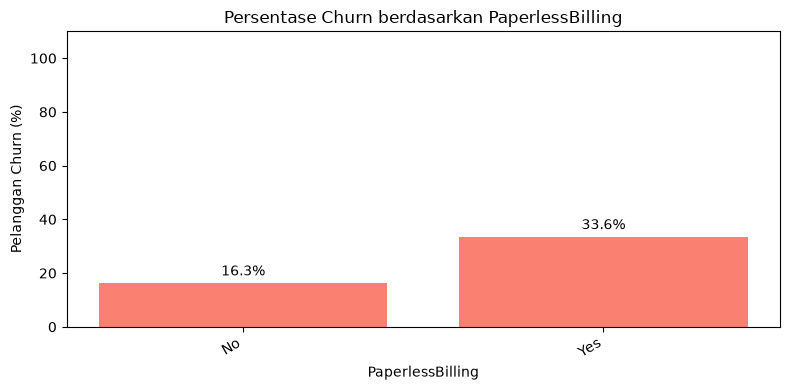

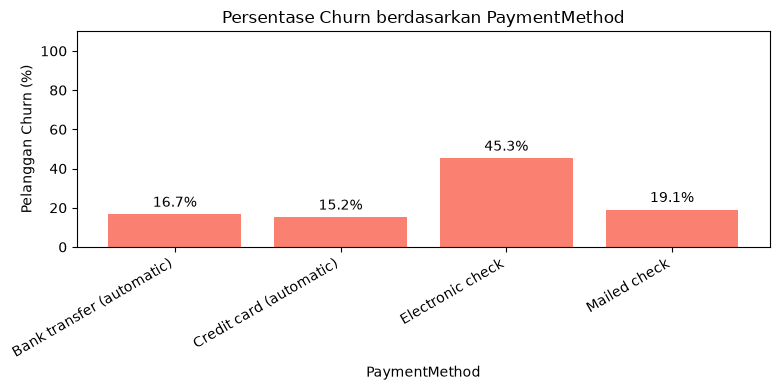

In [47]:
for kolom in kolom_kategorikal:
    tabel = pd.crosstab(
        df[kolom],
        df["Churn"],
        normalize="index"
    ) * 100

    fig, ax = plt.subplots(figsize=(8, 4))

    batang = ax.bar(
        tabel.index.astype(str),
        tabel["Yes"],
        color="salmon"
    )

    ax.bar_label(batang, fmt="%.1f%%", padding=3)
    ax.set_title(f"Persentase Churn berdasarkan {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Pelanggan Churn (%)")
    ax.set_ylim(0, 110)

    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [48]:
import numpy as np
from sklearn.impute import SimpleImputer

df_preprocessing = df.copy()
df_preprocessing[kolom_numerik] = df_preprocessing[kolom_numerik].apply(
    pd.to_numeric, errors="coerce"
)
df_preprocessing[kolom_kategorikal] = df_preprocessing[kolom_kategorikal].replace(
    r"^\s*$", np.nan, regex=True
)

imputer_numerik = SimpleImputer(strategy="median")
imputer_kategorikal = SimpleImputer(strategy="most_frequent")

print("Missing value sebelum imputasi:")
display(df_preprocessing[kolom_numerik + kolom_kategorikal].isna().sum())

Missing value sebelum imputasi:


tenure               0
MonthlyCharges       0
TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
dtype: int64

In [49]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

print("Kolom yang akan di-one-hot encoding:", kolom_kategorikal)

Kolom yang akan di-one-hot encoding: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [50]:
from sklearn.model_selection import train_test_split

X = df_preprocessing[kolom_numerik + kolom_kategorikal].copy()
y = df_preprocessing["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Target Churn memiliki nilai kosong atau label selain No/Yes.")
y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Distribusi target (%): 0 = bertahan, 1 = churn")
display(pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100
}).round(2))

Ukuran X_train: (5634, 19)
Ukuran X_test : (1409, 19)
Distribusi target (%): 0 = bertahan, 1 = churn


,Train (%),Test (%)
Churn,,
0,73.46,73.46
1,26.54,26.54


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [51]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

pipeline_numerik = Pipeline([
    ("imputer", imputer_numerik),
    ("scaler", StandardScaler())
])
pipeline_kategorikal = Pipeline([
    ("imputer", imputer_kategorikal),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("numerik", pipeline_numerik, kolom_numerik),
    ("kategorikal", pipeline_kategorikal, kolom_kategorikal)
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

nama_fitur = preprocessor.get_feature_names_out()
print("Ukuran train setelah preprocessing:", X_train_scaled.shape)
print("Ukuran test setelah preprocessing :", X_test_scaled.shape)
print("Missing pada train:", np.isnan(X_train_scaled).sum())
print("Missing pada test :", np.isnan(X_test_scaled).sum())

display(pd.DataFrame(
    X_train_scaled, columns=nama_fitur, index=X_train.index
).head())

Ukuran train setelah preprocessing: (5634, 46)
Ukuran test setelah preprocessing : (1409, 46)
Missing pada train: 0
Missing pada test : 0


,numerik__tenure,numerik__MonthlyCharges,numerik__TotalCharges,kategorikal__gender_Female,kategorikal__gender_Male,kategorikal__SeniorCitizen_0,kategorikal__SeniorCitizen_1,kategorikal__Partner_No,kategorikal__Partner_Yes,kategorikal__Dependents_No,...,kategorikal__StreamingMovies_Yes,kategorikal__Contract_Month-to-month,kategorikal__Contract_One year,kategorikal__Contract_Two year,kategorikal__PaperlessBilling_No,kategorikal__PaperlessBilling_Yes,kategorikal__PaymentMethod_Bank transfer (automatic),kategorikal__PaymentMethod_Credit card (automatic),kategorikal__PaymentMethod_Electronic check,kategorikal__PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.263290,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.504815,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.751214,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,-0.173700,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,-0.990851,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [52]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

RANDOM_STATE = 42
MAX_ITER = 500
ALPHA = 0.0001

model_baseline = MLPClassifier(
    hidden_layer_sizes=(10,), activation="relu",
    solver="adam", max_iter=MAX_ITER, alpha=ALPHA,
    random_state=RANDOM_STATE
)
model_baseline.fit(X_train_scaled, y_train)
print("Jumlah iterasi baseline:", model_baseline.n_iter_)
print("Loss akhir baseline:", model_baseline.loss_)

Jumlah iterasi baseline: 221
Loss akhir baseline: 0.3968218928632928


In [53]:
y_pred_baseline = model_baseline.predict(X_test_scaled)
print(f"Akurasi train baseline: {model_baseline.score(X_train_scaled, y_train):.4f}")
print(f"Akurasi test baseline : {accuracy_score(y_test, y_pred_baseline):.4f}")
display(pd.DataFrame({
    "Aktual": np.asarray(y_test),
    "Prediksi": y_pred_baseline
}, index=y_test.index).head(10))

Akurasi train baseline: 0.8163
Akurasi test baseline : 0.7949


,Aktual,Prediksi
437,0,0
2280,0,1
2235,0,0
4460,0,0
3761,0,0
5748,0,1
3568,0,0
2976,0,0
5928,0,0
1639,1,0


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [54]:
model_aktivasi = {}
for aktivasi in ["relu", "tanh", "logistic"]:
    model = MLPClassifier(
        hidden_layer_sizes=(10,), activation=aktivasi,
        solver="adam", max_iter=MAX_ITER, alpha=ALPHA,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_scaled, y_train)
    model_aktivasi[aktivasi] = model
    print(f"{aktivasi}: {model.n_iter_} iterasi, loss akhir = {model.loss_:.4f}")

relu: 221 iterasi, loss akhir = 0.3968
tanh: 357 iterasi, loss akhir = 0.3846
logistic: 284 iterasi, loss akhir = 0.4036


In [55]:
hasil_aktivasi = []
for aktivasi, model in model_aktivasi.items():
    hasil_aktivasi.append({
        "Aktivasi": aktivasi,
        "Akurasi Train": model.score(X_train_scaled, y_train),
        "Akurasi Test": model.score(X_test_scaled, y_test),
        "Iterasi": model.n_iter_
    })

tabel_aktivasi = pd.DataFrame(hasil_aktivasi)
tabel_aktivasi["Gap Train-Test"] = (
    tabel_aktivasi["Akurasi Train"] - tabel_aktivasi["Akurasi Test"]
)
display(tabel_aktivasi.round(4))

aktivasi_terbaik = tabel_aktivasi.loc[
    tabel_aktivasi["Akurasi Test"].idxmax(), "Aktivasi"
]
model_aktivasi_terbaik = model_aktivasi[aktivasi_terbaik]
print("Aktivasi terpilih:", aktivasi_terbaik)
print("Catatan: test dipakai untuk memilih model sesuai tugas; skor test ini")
print("bukan estimasi final independen. Untuk studi lanjutan, gunakan validasi/CV")
print("untuk pemilihan model dan simpan test untuk evaluasi akhir saja.")

,Aktivasi,Akurasi Train,Akurasi Test,Iterasi,Gap Train-Test
0,relu,0.8163,0.7949,221,0.0214
1,tanh,0.8197,0.7913,357,0.0283
2,logistic,0.8138,0.8027,284,0.0111


Aktivasi terpilih: logistic
Catatan: test dipakai untuk memilih model sesuai tugas; skor test ini
bukan estimasi final independen. Untuk studi lanjutan, gunakan validasi/CV
untuk pemilihan model dan simpan test untuk evaluasi akhir saja.


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [56]:
daftar_arsitektur = [(2,), (5,), (10,), (50,), (100, 50)]
model_arsitektur = {}

for arsitektur in daftar_arsitektur:
    model = MLPClassifier(
        hidden_layer_sizes=arsitektur, activation=aktivasi_terbaik,
        solver="adam", max_iter=MAX_ITER, alpha=ALPHA,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_scaled, y_train)
    model_arsitektur[arsitektur] = model
    print(f"{arsitektur}: {model.n_iter_} iterasi, loss akhir = {model.loss_:.4f}")

(2,): 215 iterasi, loss akhir = 0.4133
(5,): 264 iterasi, loss akhir = 0.4055
(10,): 284 iterasi, loss akhir = 0.4036
(50,): 138 iterasi, loss akhir = 0.4085
(100, 50): 500 iterasi, loss akhir = 0.3647


c:\Users\prima\Tugas Kuliah\Semester 3\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [57]:
hasil_arsitektur = []
for arsitektur, model in model_arsitektur.items():
    hasil_arsitektur.append({
        "Arsitektur": str(arsitektur),
        "Akurasi Train": model.score(X_train_scaled, y_train),
        "Akurasi Test": model.score(X_test_scaled, y_test),
        "Iterasi": model.n_iter_
    })

tabel_arsitektur = pd.DataFrame(hasil_arsitektur)
tabel_arsitektur["Gap Train-Test"] = (
    tabel_arsitektur["Akurasi Train"] - tabel_arsitektur["Akurasi Test"]
)
display(tabel_arsitektur.round(4))

indeks_terbaik = tabel_arsitektur["Akurasi Test"].idxmax()
arsitektur_terbaik = daftar_arsitektur[indeks_terbaik]
model_arsitektur_terbaik = model_arsitektur[arsitektur_terbaik]
print("Arsitektur terpilih:", arsitektur_terbaik)

,Arsitektur,Akurasi Train,Akurasi Test,Iterasi,Gap Train-Test
0,"(2,)",0.8074,0.8006,215,0.0069
1,"(5,)",0.8101,0.8034,264,0.0067
2,"(10,)",0.8138,0.8027,284,0.0111
3,"(50,)",0.8103,0.8013,138,0.0090
4,"(100, 50)",0.8305,0.7814,500,0.0491


Arsitektur terpilih: (5,)


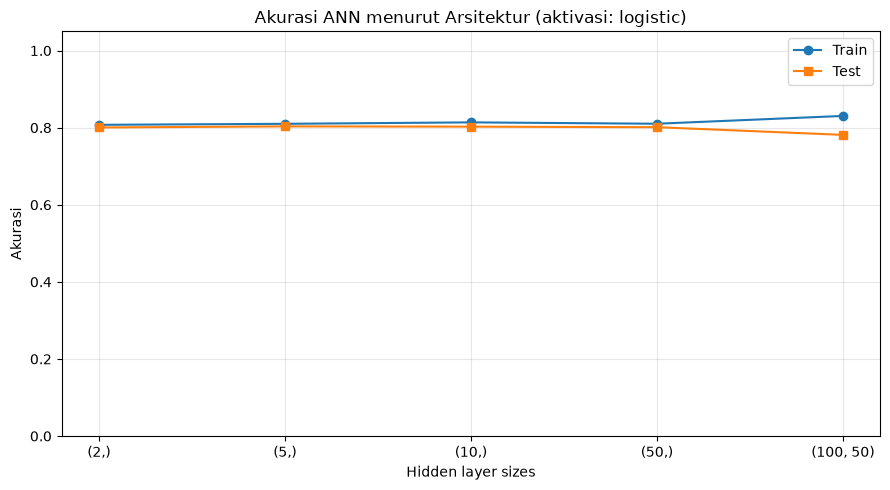

In [58]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabel_arsitektur["Arsitektur"], tabel_arsitektur["Akurasi Train"],
        marker="o", label="Train")
ax.plot(tabel_arsitektur["Arsitektur"], tabel_arsitektur["Akurasi Test"],
        marker="s", label="Test")
ax.set_title(f"Akurasi ANN menurut Arsitektur (aktivasi: {aktivasi_terbaik})")
ax.set_xlabel("Hidden layer sizes")
ax.set_ylabel("Akurasi")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Evaluasi Model

In [59]:
model_evaluasi = {
    "Aktivasi terbaik (3.2)": model_aktivasi_terbaik,
    "Arsitektur terbaik (3.3)": model_arsitektur_terbaik
}

hasil_evaluasi = []
prediksi_evaluasi = {}
for nama, model in model_evaluasi.items():
    prediksi = model.predict(X_test_scaled)
    prediksi_evaluasi[nama] = prediksi
    hasil_evaluasi.append({
        "Eksperimen": nama,
        "Aktivasi": model.activation,
        "Arsitektur": str(model.hidden_layer_sizes),
        "Accuracy": accuracy_score(y_test, prediksi),
        "Precision": precision_score(y_test, prediksi, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, prediksi, pos_label=1, zero_division=0),
        "F1-Score": f1_score(y_test, prediksi, pos_label=1, zero_division=0)
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi)
display(tabel_evaluasi.round(4))
print("Precision, recall, dan F1 menggunakan kelas positif 1 = churn.")
print("Jika tidak ada prediksi positif, precision ditetapkan 0 (zero_division=0).")
print(f"Akurasi pembanding kelas mayoritas train pada test: ")
print(f"{accuracy_score(y_test, np.full(len(y_test), y_train.mode().iloc[0])):.4f}")

nama_model_terbaik = tabel_evaluasi.loc[
    tabel_evaluasi["Accuracy"].idxmax(), "Eksperimen"
]
model_terbaik = model_evaluasi[nama_model_terbaik]
print("Model terpilih berdasarkan accuracy:", nama_model_terbaik)


,Eksperimen,Aktivasi,Arsitektur,Accuracy,Precision,Recall,F1-Score
0,Aktivasi terbaik (3.2),logistic,"(10,)",0.8027,0.6655,0.5160,0.5813
1,Arsitektur terbaik (3.3),logistic,"(5,)",0.8034,0.6655,0.5214,0.5847


Precision, recall, dan F1 menggunakan kelas positif 1 = churn.
Jika tidak ada prediksi positif, precision ditetapkan 0 (zero_division=0).
Akurasi pembanding kelas mayoritas train pada test: 
0.7346
Model terpilih berdasarkan accuracy: Arsitektur terbaik (3.3)


Aktivasi terbaik (3.2): TN=938, FP=97, FN=181, TP=193
Arsitektur terbaik (3.3): TN=937, FP=98, FN=179, TP=195


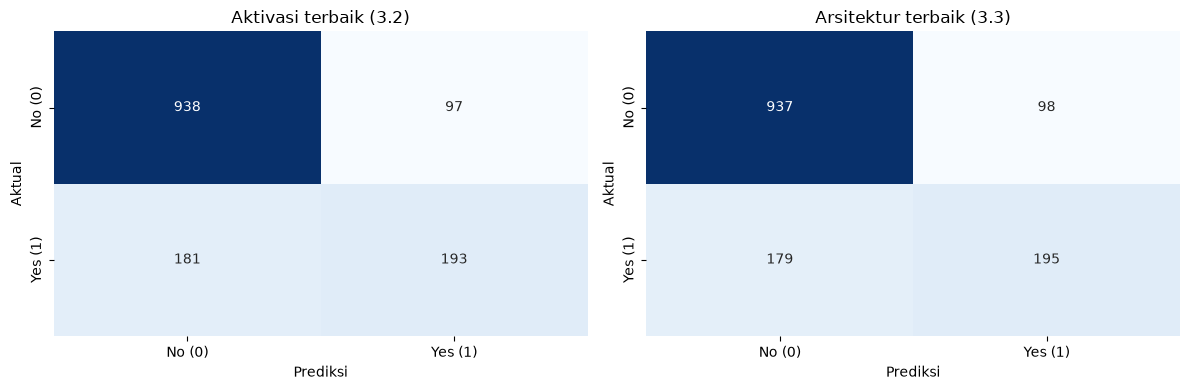

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nama, prediksi) in zip(axes, prediksi_evaluasi.items()):
    cm = confusion_matrix(y_test, prediksi, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No (0)", "Yes (1)"],
        yticklabels=["No (0)", "Yes (1)"], ax=ax
    )
    ax.set_title(nama)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    tn, fp, fn, tp = cm.ravel()
    print(f"{nama}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
plt.tight_layout()
plt.show()

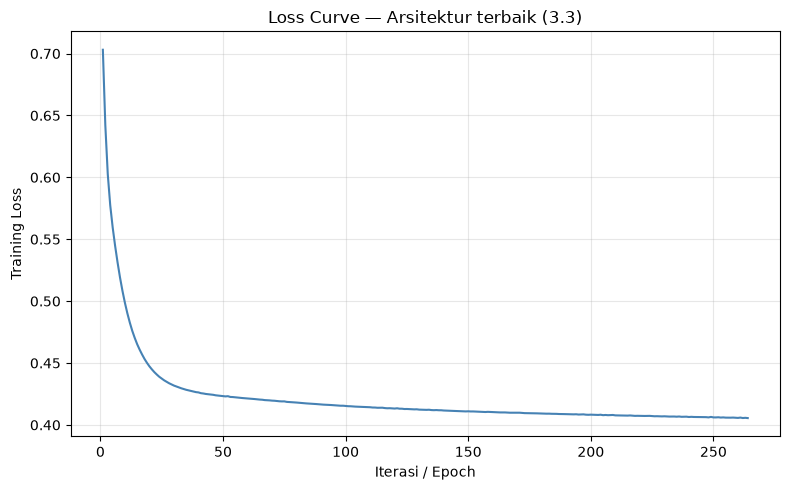

Aktivasi: logistic
Arsitektur: (5,)
Iterasi aktual: 264
Batas iterasi: 500
Loss akhir: 0.405531


,Iterasi,Training Loss
0,255,0.405890
1,256,0.405868
2,257,0.405860
3,258,0.405940
4,259,0.405765
5,260,0.405673
6,261,0.405929
7,262,0.405578
8,263,0.405743
9,264,0.405531


Training berhenti sebelum batas iterasi sesuai kriteria toleransi model.
Loss train yang mendatar tidak otomatis membuktikan generalisasi baik;
bandingkan juga performa train dan test.


In [61]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(model_terbaik.loss_curve_) + 1),
        model_terbaik.loss_curve_, color="steelblue")
ax.set_title(f"Loss Curve — {nama_model_terbaik}")
ax.set_xlabel("Iterasi / Epoch")
ax.set_ylabel("Training Loss")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Aktivasi:", model_terbaik.activation)
print("Arsitektur:", model_terbaik.hidden_layer_sizes)
print("Iterasi aktual:", model_terbaik.n_iter_)
print("Batas iterasi:", model_terbaik.max_iter)
print(f"Loss akhir: {model_terbaik.loss_:.6f}")
display(pd.DataFrame({
    "Iterasi": range(max(1, model_terbaik.n_iter_ - 9), model_terbaik.n_iter_ + 1),
    "Training Loss": model_terbaik.loss_curve_[-10:]
}))
if model_terbaik.n_iter_ >= model_terbaik.max_iter:
    print("Batas iterasi tercapai. Periksa apakah loss masih menurun;")
    print("jika masih menurun nyata, coba tambah max_iter pada eksperimen berikutnya.")
else:
    print("Training berhenti sebelum batas iterasi sesuai kriteria toleransi model.")
print("Loss train yang mendatar tidak otomatis membuktikan generalisasi baik;")
print("bandingkan juga performa train dan test.")

## 5. Analisis

### 5.1 Preprocessing Data

Dataset terdiri atas **7.043 pelanggan dan 21 kolom**. Setelah kolom `customerID` dan target `Churn` dipisahkan, terdapat **19 fitur**, yaitu 3 fitur numerik dan 16 fitur kategorikal.

Pemeriksaan awal tidak mendeteksi missing value. Namun, setelah `TotalCharges` dikonversi menjadi numerik, ditemukan **11 nilai yang tidak dapat dibaca sebagai angka**. Nilai tersebut ditangani menggunakan median dari data train. Strategi imputasi modus juga disiapkan untuk fitur kategorikal, meskipun tidak ditemukan missing value pada fitur tersebut.

One-hot encoding digunakan untuk mengubah kategori menjadi indikator numerik tanpa menciptakan urutan antar kategori. StandardScaler diterapkan pada fitur numerik agar perbedaan skala tidak mendominasi pembelajaran ANN. Setelah preprocessing, jumlah fitur menjadi **46**, tanpa missing value pada train maupun test.

Data dibagi menjadi **5.634 sampel train dan 1.409 sampel test**, menggunakan perbandingan 80:20 dan `stratify=y`. Proporsi kelas tetap sekitar **73,46% pelanggan bertahan** dan **26,54% pelanggan churn**. Seluruh parameter preprocessing dipelajari hanya dari train untuk mencegah kebocoran informasi dari test.

Namun, karena belum dilakukan eksperimen pembanding tanpa scaling atau dengan strategi imputasi lain, besarnya pengaruh setiap teknik preprocessing terhadap performa belum dapat disimpulkan secara kuantitatif.

### 5.2 Perbandingan Fungsi Aktivasi

Eksperimen menggunakan satu hidden layer berisi 10 neuron dengan hyperparameter lain yang sama.

| Fungsi aktivasi | Akurasi train | Akurasi test | Gap train–test (poin persentase) | Iterasi |
|---|---:|---:|---:|---:|
| ReLU | 81,63% | 79,49% | 2,14 | 221 |
| Tanh | 81,97% | 79,13% | 2,83 | 357 |
| Logistic | 81,38% | **80,27%** | **1,11** | 284 |

> Gap dihitung sebelum pembulatan sehingga dapat sedikit berbeda dari hasil pengurangan persentase yang ditampilkan.

Aktivasi **Logistic menghasilkan akurasi test tertinggi**, yaitu 80,27%, sekaligus gap terkecil. Keunggulannya dibandingkan ReLU sekitar 0,78 poin persentase dan dibandingkan Tanh sekitar 1,14 poin persentase.

Tanh menghasilkan akurasi train tertinggi, tetapi akurasi test terendah. Loss akhir Tanh juga lebih rendah, yaitu 0,3846, dibandingkan ReLU sebesar 0,3968 dan Logistic sebesar 0,4036. Hal ini menunjukkan bahwa **loss train yang lebih rendah dan akurasi train yang lebih tinggi tidak otomatis menghasilkan performa test yang lebih baik**.

Perbedaan fungsi aktivasi memengaruhi keluaran neuron dan proses pembaruan bobot, sehingga model dapat mempelajari pola yang berbeda. Dalam konfigurasi ini, Logistic menunjukkan hasil generalisasi yang lebih baik berdasarkan skor test. Namun, hasil tersebut tidak membuktikan bahwa Logistic selalu lebih unggul pada seluruh dataset atau arsitektur.

Perbedaan performa **belum dapat disebut signifikan secara statistik**, karena eksperimen hanya menggunakan satu pembagian data dan belum dilakukan pengujian statistik maupun pengulangan dengan beberapa random seed.

### 5.3 Pengaruh Ukuran Arsitektur terhadap Overfitting

Eksperimen berikutnya menggunakan aktivasi Logistic dengan variasi jumlah neuron dan hidden layer.

| Arsitektur | Akurasi train | Akurasi test | Gap train–test (poin persentase) | Iterasi |
|---|---:|---:|---:|---:|
| `(2,)` | 80,74% | 80,06% | 0,69 | 215 |
| `(5,)` | 81,01% | **80,34%** | **0,67** | 264 |
| `(10,)` | 81,38% | 80,27% | 1,11 | 284 |
| `(50,)` | 81,03% | 80,13% | 0,90 | 138 |
| `(100, 50)` | **83,05%** | 78,14% | **4,91** | 500 |

Arsitektur **`(5,)` menghasilkan akurasi test tertinggi**, yaitu 80,34%, dengan gap train–test terkecil. Hasil ini menunjukkan bahwa jaringan sederhana sudah mampu memberikan performa yang kompetitif pada konfigurasi yang digunakan.

Penambahan neuron tidak meningkatkan akurasi test secara konsisten. Indikasi overfitting paling jelas terlihat pada arsitektur **`(100, 50)`**, karena akurasi train mencapai 83,05%, tetapi akurasi test turun menjadi 78,14%. Gap sebesar 4,91 poin persentase menunjukkan perbedaan kemampuan model pada data training dan data yang tidak digunakan untuk training.

Dibandingkan arsitektur `(5,)`, jaringan `(100, 50)` meningkatkan akurasi train sekitar 2,04 poin persentase, tetapi menurunkan akurasi test sekitar 2,20 poin persentase. Pola ini mengindikasikan bahwa peningkatan kapasitas model membuatnya lebih menyesuaikan diri dengan karakteristik data train tanpa meningkatkan generalisasi.

Model `(100, 50)` juga mencapai batas **500 iterasi** dan menghasilkan `ConvergenceWarning`. Artinya, kriteria konvergensi belum terpenuhi. Menambah iterasi mungkin menurunkan loss train, tetapi belum tentu memperbaiki akurasi test atau mengatasi overfitting.

Eksperimen ini mengubah kapasitas jaringan, sedangkan nilai `alpha` dipertahankan sama. Oleh karena itu, pengaruh kekuatan regularisasi L2 belum diuji secara terpisah.

### 5.4 Evaluasi Model Terbaik

Hasil evaluasi model terbaik dari eksperimen aktivasi dan arsitektur adalah sebagai berikut.

| Model | Accuracy | Precision churn | Recall churn | F1-score churn |
|---|---:|---:|---:|---:|
| Logistic `(10,)` | 80,27% | 66,55% | 51,60% | 58,13% |
| Logistic `(5,)` | **80,34%** | **66,55%** | **52,14%** | **58,47%** |

Model Logistic `(5,)` unggul tipis pada accuracy, recall, dan F1-score. Precision kedua model sama pada pembulatan yang ditampilkan.

Meskipun demikian, selisih accuracy hanya sekitar **0,07 poin persentase**, setara dengan **satu prediksi benar tambahan dari 1.409 sampel test**. Oleh karena itu, keunggulan model `(5,)` belum cukup untuk membuktikan bahwa model tersebut akan selalu lebih baik pada pembagian data lainnya.

Confusion matrix kedua model memperlihatkan:

| Model | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| Logistic `(10,)` | 938 | 97 | 181 | 193 |
| Logistic `(5,)` | 937 | 98 | 179 | 195 |

Pada model Logistic `(5,)`:

- **TN = 937:** pelanggan bertahan yang diprediksi bertahan.
- **FP = 98:** pelanggan bertahan yang keliru diprediksi churn.
- **FN = 179:** pelanggan churn yang keliru diprediksi bertahan.
- **TP = 195:** pelanggan churn yang berhasil diprediksi churn.

Dari **374 pelanggan yang benar-benar churn**, model mendeteksi 195 pelanggan atau **52,14%**. Sebanyak 179 pelanggan atau sekitar **47,86% masih terlewat**. Sementara itu, dari 293 pelanggan yang diprediksi churn, sebanyak 195 benar-benar churn, sehingga precision mencapai 66,55%.

Dalam penerapan retensi pelanggan, false negative berpotensi membuat pelanggan berisiko tidak mendapatkan tindakan pencegahan. Sebaliknya, false positive dapat menyebabkan perusahaan memberikan penawaran retensi kepada pelanggan yang sebenarnya tetap bertahan.

Akurasi model sebesar 80,34% lebih tinggi sekitar **6,88 poin persentase** dibandingkan pembanding yang selalu memprediksi kelas mayoritas, yaitu 73,46%. Model memberikan tambahan kemampuan prediksi, tetapi recall yang masih rendah menunjukkan bahwa **accuracy saja belum cukup untuk menilai keberhasilannya dalam mendeteksi churn**.

### 5.5 Analisis Loss Curve dan Konvergensi

Model Logistic `(5,)` berhenti pada **iterasi ke-264**, sebelum mencapai batas 500 iterasi, dengan loss akhir sebesar **0,405531**.

Pada sepuluh iterasi terakhir, loss berfluktuasi kecil dari 0,405890 pada iterasi 255 menjadi 0,405531 pada iterasi 264. Penurunan bersihnya hanya sekitar **0,000359**, yang menunjukkan bahwa perbaikan loss mulai kecil pada akhir training.

Hasil tersebut konsisten dengan penghentian training berdasarkan kriteria toleransi model. Namun, hal ini tidak membuktikan bahwa model mencapai optimum global. Loss train yang stabil juga tidak otomatis menunjukkan performa generalisasi yang baik, sehingga tetap perlu dibandingkan dengan hasil evaluasi.

Jika loss masih menurun tajam ketika `max_iter` tercapai, langkah yang dapat dicoba adalah menambah jumlah iterasi atau menyesuaikan learning rate dan solver. Perubahan tersebut perlu dinilai menggunakan data validasi agar penurunan loss train tidak disalahartikan sebagai peningkatan kemampuan generalisasi.

### 5.6 Keterbatasan Eksperimen

Pemilihan aktivasi dan arsitektur dilakukan berdasarkan akurasi test sesuai instruksi tugas. Dengan demikian, **data test sudah ikut digunakan dalam pemilihan model**, sehingga hasilnya bukan evaluasi akhir yang sepenuhnya independen.

Selain itu, eksperimen hanya menggunakan satu pembagian data dan satu `random_state`. Hasilnya belum menunjukkan kestabilan performa pada pembagian data atau inisialisasi bobot yang berbeda. Kesimpulan model terbaik karena itu terbatas pada konfigurasi eksperimen yang dilakukan.

## 6. Kesimpulan dan Saran

### 6.1 Kesimpulan

1. Preprocessing berhasil menghasilkan **46 fitur** tanpa missing value pada data train maupun test. Imputasi, encoding, dan scaling dipelajari hanya dari data train untuk mencegah kebocoran informasi saat preprocessing.

2. Pada arsitektur `(10,)`, aktivasi **Logistic memberikan akurasi test tertinggi sebesar 80,27%**, dibandingkan ReLU sebesar 79,49% dan Tanh sebesar 79,13%. Namun, perbedaannya belum diuji secara statistik.

3. Model terbaik berdasarkan akurasi test adalah **ANN dengan aktivasi Logistic dan satu hidden layer berisi 5 neuron**. Model ini menghasilkan accuracy **80,34%**, precision **66,55%**, recall **52,14%**, dan F1-score **58,47%** untuk kelas churn.

4. Penambahan ukuran jaringan tidak selalu meningkatkan performa. Arsitektur `(100, 50)` menunjukkan indikasi overfitting, dengan akurasi train 83,05% dan akurasi test 78,14%. Model tersebut juga belum memenuhi kriteria konvergensi saat mencapai 500 iterasi.

5. Model Logistic `(5,)` berhenti pada 264 iterasi dengan perubahan loss yang kecil pada akhir training. Walaupun melampaui akurasi pembanding kelas mayoritas, model masih melewatkan **179 dari 374 pelanggan churn**, sehingga kemampuan deteksi churn perlu ditingkatkan.

6. Keunggulan model terbaik masih bersifat sementara karena selisih terhadap Logistic `(10,)` sangat kecil dan data test digunakan untuk memilih model. Pengujian lebih lanjut diperlukan untuk memastikan generalisasinya.

### 6.2 Saran

1. **Gunakan data validasi atau cross-validation untuk pemilihan model.**  
   Pilih aktivasi, arsitektur, dan hyperparameter berdasarkan hasil validasi. Simpan test untuk evaluasi akhir. Saat cross-validation, gabungkan preprocessing dan ANN dalam satu pipeline agar seluruh parameter preprocessing dipelajari hanya dari bagian train setiap fold.

2. **Utamakan metrik yang sesuai dengan tujuan deteksi churn.**  
   Selain accuracy, perhatikan recall, precision, F1-score, dan PR-AUC. Jika prioritasnya mengurangi pelanggan churn yang terlewat, uji penyesuaian ambang probabilitas pada data validasi. Penurunan ambang dapat meningkatkan recall, tetapi berpotensi menambah false positive.

3. **Uji regularisasi untuk mengendalikan overfitting.**  
   Bandingkan beberapa nilai `alpha`, misalnya 0,0001; 0,001; 0,01; dan 0,1. Pertimbangkan juga `early_stopping`, terutama pada jaringan berkapasitas besar. Pilih konfigurasi berdasarkan performa validasi.

4. **Tinjau konfigurasi optimasi pada model yang belum konvergen.**  
   Untuk model yang menghasilkan `ConvergenceWarning`, coba tingkatkan `max_iter`, sesuaikan `learning_rate_init`, atau bandingkan solver lain. Pantau loss dan skor validasi, karena menambah iterasi tidak otomatis mengatasi overfitting.

5. **Ulangi eksperimen untuk menilai kestabilan hasil.**  
   Gunakan beberapa random seed atau repeated stratified cross-validation, kemudian laporkan rata-rata dan penyebaran skor. Hal ini penting karena selisih akurasi model terbaik hanya setara satu prediksi benar tambahan.

6. **Bandingkan dengan model dan strategi preprocessing lain.**  
   Gunakan Logistic Regression atau model pohon sebagai pembanding. Untuk mengukur manfaat preprocessing, lakukan eksperimen terkontrol dengan alternatif scaling atau imputasi. Jika mencoba oversampling, terapkan hanya pada bagian train setiap fold.

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.